# 04 · Model Training and Evaluation

**Goal:** rank active customers by their risk of making no booking in the next 60 days, with
probabilities trustworthy enough to sort them into High / Medium / Low risk groups.

### How we judge models, and why not accuracy

Only about 16% of customers churn. A "model" that says *nobody churns* is 84% accurate and completely
useless. So we use:

| Metric | Question it answers |
|---|---|
| **ROC-AUC** | How well does the model rank churners above non-churners overall? (0.5 = random) |
| **PR-AUC** | The same, but focused on the churners. Stricter when churners are rare. **Main selection metric.** |
| **Precision / recall / lift @ top 10%** | If retention can only contact the riskiest 10%, how many are real churners, what share of all churners is that, and how much better is it than picking at random? |
| **Brier score** | Are the probabilities honest? If the model says 30%, do about 30% churn? Lower is better. |

### The rules we follow
1. **Choose on validation, report on test.** Every model comparison and setting is decided on the
   validation snapshot. The test snapshots are used **once**, at the end. Otherwise the test score
   is no longer an honest estimate.
2. **Beat a simple baseline first.** If a model can't beat "sort by days silent", it isn't worth
   the complexity.

> ⚠️ **Synthetic data.** These scores show the pipeline works. They are **not** estimates of how well
> a model will work on Snabbit's real customers.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

import config
import modeling as m
import train as train_script

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

table = pd.read_csv(config.PROCESSED_DIR / "features.csv", parse_dates=["as_of"])
train, valid, test = (table[table["split"] == s] for s in ("train", "valid", "test"))
X_train, y_train = train[m.FEATURES], train[m.TARGET]
X_valid, y_valid = valid[m.FEATURES], valid[m.TARGET]

pd.DataFrame({s: [len(d), d["churned"].mean()] for s, d in [("train", train), ("valid", valid), ("test", test)]},
             index=["rows", "churn_rate"]).T

,rows,churn_rate
train,51694.0,0.162
valid,6494.0,0.165
test,21000.0,0.164


### A note on class imbalance

16% churners is imbalanced but not extreme. We **don't** reweight or resample. Those tricks
distort predicted probabilities (a reweighted model overstates risk), and we need honest
probabilities for the risk groups. Ranking metrics like PR-AUC already focus on the rare class.

## 1 · Baselines and candidate models (validation)

In [2]:
scores = {
    "baseline: days silent": valid["recency_days"],
    "baseline: silence ÷ usual gap": valid["recency_vs_typical_gap"],
}
models = m.make_models()
for name, model in models.items():
    model.fit(X_train, y_train)
    scores[name] = model.predict_proba(X_valid)[:, 1]

results = pd.DataFrame({name: m.evaluate(y_valid, s) for name, s in scores.items()}).T
results

,roc_auc,pr_auc,precision_top10%,recall_top10%,lift_top10%,brier
baseline: days silent,0.843,0.611,0.732,0.443,4.430,NaN
baseline: silence ÷ usual gap,0.800,0.594,0.709,0.429,4.290,NaN
logistic_regression,0.893,0.698,0.780,0.472,4.719,0.082
decision_tree,0.888,0.680,0.773,0.468,4.681,0.082
random_forest,0.901,0.711,0.787,0.476,4.765,0.079
gradient_boosting,0.898,0.711,0.797,0.482,4.821,0.079


**How to read it:** every model clearly beats both baselines. ROC-AUC rises from about 0.84 to about 0.90, and
PR-AUC from 0.61 to about 0.71. The models are close to each other, though. Logistic regression,
the simplest, is only slightly behind the tree ensembles.

(Baselines show no Brier score: "days silent" is a ranking, not a probability.)

## 2 · Light tuning of gradient boosting (validation)

A few sensible settings, not an exhaustive search. With one validation month, heavy tuning
would just fit noise.

In [3]:
grid = [
    {"learning_rate": 0.03, "max_iter": 500, "max_leaf_nodes": 15, "min_samples_leaf": 100},
    {"learning_rate": 0.05, "max_iter": 300, "max_leaf_nodes": 31, "min_samples_leaf": 100},
    {"learning_rate": 0.10, "max_iter": 200, "max_leaf_nodes": 63, "min_samples_leaf": 100},
]
tuning = {}
for params in grid:
    model = m.make_gradient_boosting(**params).fit(X_train, y_train)
    tuning[str(params)] = m.evaluate(y_valid, model.predict_proba(X_valid)[:, 1])
pd.DataFrame(tuning).T

,roc_auc,pr_auc,precision_top10%,recall_top10%,lift_top10%,brier
"{'learning_rate': 0.03, 'max_iter': 500, 'max_leaf_nodes': 15, 'min_samples_leaf': 100}",0.900,0.716,0.787,0.476,4.765,0.078
"{'learning_rate': 0.05, 'max_iter': 300, 'max_leaf_nodes': 31, 'min_samples_leaf': 100}",0.898,0.711,0.797,0.482,4.821,0.079
"{'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 63, 'min_samples_leaf': 100}",0.894,0.706,0.784,0.474,4.747,0.081


Smaller trees with a slower learning rate do slightly better, a sign that the patterns are fairly
simple and bigger trees start memorising noise. The first setting is stored in
`config.MODEL_PARAMS`.

## 3 · Are the differences real?

One validation month has about 6,500 rows, and small score gaps can be luck. **Bootstrapping**
resamples the validation rows 300 times and recomputes the gap each time. If the 95% range excludes
zero, the difference is probably real.

In [4]:
best = m.make_gradient_boosting(**config.MODEL_PARAMS).fit(X_train, y_train)
scores["gradient_boosting (tuned)"] = best.predict_proba(X_valid)[:, 1]

def bootstrap_gap(a, b, n=300, seed=0):
    y, sa, sb = y_valid.to_numpy(), np.asarray(scores[a]), np.asarray(scores[b])
    rng = np.random.default_rng(seed)
    gaps = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        gaps.append(average_precision_score(y[i], sa[i]) - average_precision_score(y[i], sb[i]))
    return {"PR-AUC gap": np.mean(gaps), "95% low": np.percentile(gaps, 2.5), "95% high": np.percentile(gaps, 97.5)}

pd.DataFrame({
    f"{a}  vs  {b}": bootstrap_gap(a, b) for a, b in [
        ("gradient_boosting (tuned)", "logistic_regression"),
        ("gradient_boosting (tuned)", "random_forest"),
        ("logistic_regression", "baseline: days silent"),
    ]
}).T

,PR-AUC gap,95% low,95% high
gradient_boosting (tuned) vs logistic_regression,0.019,0.009,0.029
gradient_boosting (tuned) vs random_forest,0.005,-0.002,0.012
logistic_regression vs baseline: days silent,0.086,0.068,0.102


- **Any model vs the baseline:** a large, clearly real gain.
- **Gradient boosting vs logistic regression:** a small but real gain.
- **Gradient boosting vs random forest:** a tie.

**Choice: gradient boosting (tuned).** It has the best PR-AUC, the best Brier score and fast training.
Logistic regression stays a strong runner-up. If the business ever needs a model whose every
coefficient can be explained, it costs only about 0.02 PR-AUC.

## 4 · Are the probabilities honest? (calibration, validation)

Risk groups use probability cut-offs, so a predicted 40% should mean about 40% really churn.
Points on the diagonal mean honest probabilities.

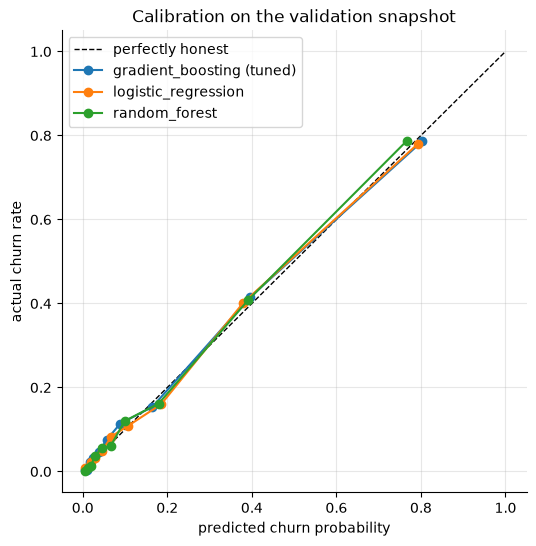

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfectly honest")
for name in ["gradient_boosting (tuned)", "logistic_regression", "random_forest"]:
    frac, mean_pred = calibration_curve(y_valid, scores[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, "o-", label=name)
ax.set(xlabel="predicted churn probability", ylabel="actual churn rate",
       title="Calibration on the validation snapshot")
ax.legend()
plt.show()

## 5 · Final model: retrain on train + validation, evaluate **once** on test

Now that every decision is made, we refit on all the labeled history before the test period
(more data, more recent) and score the three untouched test snapshots. This is the same code
`src/train.py` runs.

In [6]:
final_model, test_metrics, trained_through = train_script.train_final(table)
test_prob = final_model.predict_proba(test[m.FEATURES])[:, 1]

pd.DataFrame({
    "final model": test_metrics,
    "baseline: days silent": m.evaluate(test[m.TARGET], test["recency_days"]),
}).T

,roc_auc,pr_auc,precision_top10%,recall_top10%,lift_top10%,brier
final model,0.910,0.744,0.815,0.498,4.977,0.074
baseline: days silent,0.854,0.628,0.734,0.449,4.485,NaN


In [7]:
by_month = pd.DataFrame({
    month.date(): m.evaluate(g[m.TARGET], test_prob[test["as_of"].to_numpy() == month])
    for month, g in test.groupby("as_of")
}).T
by_month

,roc_auc,pr_auc,precision_top10%,recall_top10%,lift_top10%,brier
2026-07-01,0.911,0.737,0.811,0.513,5.135,0.072
2026-08-01,0.913,0.747,0.805,0.492,4.922,0.074
2026-09-01,0.906,0.749,0.828,0.489,4.887,0.075


Stable scores across the three test months mean the model isn't relying on something that only
held in one period.

## 6 · What this means for a retention campaign

The **gains chart** answers the practical question: *if we contact the riskiest X% of active
customers, what share of next-60-day churners do we reach?*

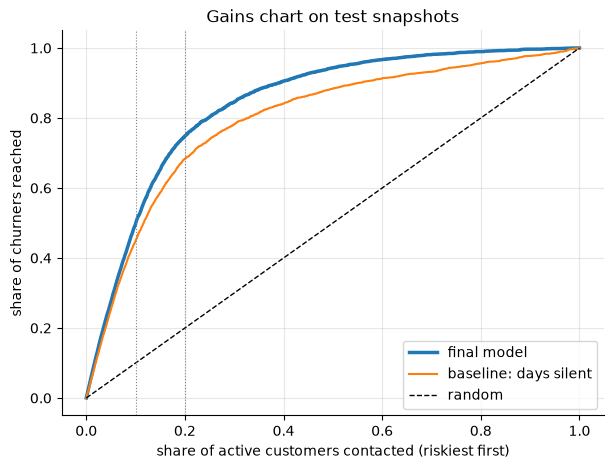

,model,baseline
top 5%,0.275,0.252
top 10%,0.498,0.449
top 20%,0.749,0.683
top 30%,0.846,0.782


In [8]:
y_test = test[m.TARGET].to_numpy()

def gains(score):
    order = np.argsort(-np.asarray(score), kind="stable")
    return np.cumsum(y_test[order]) / y_test.sum()

share = np.arange(1, len(y_test) + 1) / len(y_test)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(share, gains(test_prob), label="final model", lw=2.5)
ax.plot(share, gains(test["recency_days"]), label="baseline: days silent", lw=1.5)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random")
for x in (0.10, 0.20):
    ax.axvline(x, color="grey", lw=0.8, ls=":")
ax.set(xlabel="share of active customers contacted (riskiest first)",
       ylabel="share of churners reached", title="Gains chart on test snapshots")
ax.legend()
plt.show()

pd.DataFrame({f"top {int(x*100)}%": {"model": gains(test_prob)[int(x*len(y_test))-1],
                                     "baseline": gains(test["recency_days"])[int(x*len(y_test))-1]}
              for x in (0.05, 0.10, 0.20, 0.30)}).T

### Risk groups

Probability cut-offs from `config`: **High ≥ 50%**, **Medium 20–50%**, **Low < 20%**. These are
provisional. The right cut-offs depend on how many customers the retention team can actually
contact, and how much an intervention costs.

In [9]:
seg = m.risk_segment(test_prob, config.RISK_HIGH, config.RISK_MEDIUM)
segments = (pd.DataFrame({"segment": seg, "churned": y_test, "prob": test_prob})
              .groupby("segment", observed=True)
              .agg(customers=("churned", "size"), predicted_rate=("prob", "mean"),
                   actual_churn_rate=("churned", "mean"), churners=("churned", "sum")))
segments["share_of_customers"] = segments["customers"] / segments["customers"].sum()
segments["share_of_all_churners"] = segments["churners"] / segments["churners"].sum()
segments.loc[["High", "Medium", "Low"]]

,customers,predicted_rate,actual_churn_rate,churners,share_of_customers,share_of_all_churners
segment,,,,,,
High,2725,0.757,0.757,2064,0.130,0.600
Medium,1901,0.327,0.313,595,0.091,0.173
Low,16374,0.046,0.048,779,0.780,0.227


## 7 · What drives the predictions?

**Permutation importance:** shuffle one feature at a time and measure how much PR-AUC drops. A
big drop means the model relies on that feature. It's computed with the train-only model on
validation, so the test set stays untouched by anything that could influence decisions.

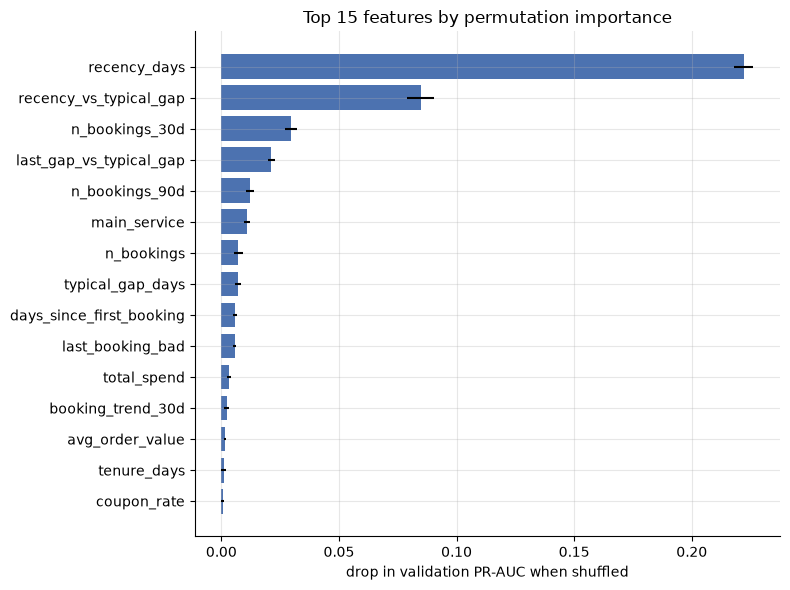

,pr_auc_drop,std
feature,,
recency_days,2.221e-01,4.086e-03
recency_vs_typical_gap,8.470e-02,5.641e-03
n_bookings_30d,2.964e-02,2.630e-03
last_gap_vs_typical_gap,2.128e-02,1.465e-03
n_bookings_90d,1.203e-02,1.664e-03
main_service,1.103e-02,1.318e-03
n_bookings,7.203e-03,1.850e-03
typical_gap_days,7.075e-03,1.220e-03
days_since_first_booking,5.932e-03,8.237e-04


In [10]:
imp = permutation_importance(best, X_valid, y_valid, scoring="average_precision",
                             n_repeats=5, random_state=m.SEED, n_jobs=-1)
importance = (pd.DataFrame({"feature": m.FEATURES, "pr_auc_drop": imp.importances_mean,
                            "std": imp.importances_std})
                .sort_values("pr_auc_drop", ascending=False).set_index("feature"))

top = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["pr_auc_drop"], xerr=top["std"], color="#4C72B0")
ax.set(xlabel="drop in validation PR-AUC when shuffled", title="Top 15 features by permutation importance")
plt.tight_layout()
plt.show()
importance.head(15)

## 8 · Conclusions (synthetic data, provisional)

**1. The model works, and the pipeline is complete end to end.** On the untouched test months:
ROC-AUC **0.91**, PR-AUC **0.74**, stable across all three months. Saved as `models/churn_model.joblib`
by `src/train.py`.

**2. It beats the simple baseline, but by a moderate margin.** Sorting by days silent already reaches
45% of churners in the top 10%; the model reaches **50%**, and 75% vs 68% in the top 20%. Most of the
signal is silence. The model adds the rest: rhythm, trend and a bad last booking.

**3. The probabilities are honest.** Predicted and actual churn rates match closely (High group:
75.7% predicted, 75.7% actual). So the risk groups mean what they say:

| Group | Share of active customers | Actual churn rate | Share of all churners |
|---|---:|---:|---:|
| High (≥ 50%) | 13% | 76% | 60% |
| Medium (20–50%) | 9% | 31% | 17% |
| Low (< 20%) | 78% | 5% | 23% |

**4. Gradient boosting won, but narrowly.** It beat logistic regression by a small but real margin
(PR-AUC +0.019) and tied with random forest. Logistic regression is a credible fallback if
explainability is ever required.

**5. What the model relies on:** days silent, by far, then silence relative to the customer's usual
gap, recent booking counts, and the last gap vs their usual gap (the "fading" signal). Main service and a
bad last booking follow. That matches the behaviour we built into the generator, which is a
useful sanity check that the model learns real patterns and not artefacts.

### Important caveats before anyone acts on a real version of this
- **Synthetic scores are optimistic.** The generator follows a few clean rules, and real customers
  are messier. Expect lower numbers on Snabbit's data.
- **"Likely to churn" ≠ "can be saved".** Many High-risk customers have been silent for 45–59 days and
  may already be gone. The Medium group, and High-risk customers who are only *starting* to drift,
  may be where retention actually pays off. Measuring that needs a controlled test:
  contact some at-risk customers and hold back a comparable group.
- **Risk cut-offs should follow capacity.** If the team can contact 500 customers a week, the "High"
  threshold should be whatever selects the riskiest 500.
- **Models go stale.** Retrain regularly (for example monthly) and check that test-style metrics hold up.
